# 18 — Gradient Boosting Classifier (Classification Track — Part B)
**23CSE301 Machine Learning — Capstone, Review 2**

**Dataset:** Employee promotion (`train.csv`) **Target:** `is_promoted` (1 = promoted, 0 = not promoted)

| Block | Rubric section |
|---|---|
| 1 | Section A — Dataset & EDA *(repeated from Review 1 so the notebook runs standalone)* |
| 2 | Section B — Preprocessing & Feature Engineering *(identical split, so all 10 models are comparable)* |
| 3 | Review 2, Section A — Classification Track, Part B (Gradient Boosting) |

Gradient Boosting also builds trees in sequence, but instead of re-weighting rows it fits each new tree to the **gradient of the loss** — in effect, to what the ensemble still gets wrong. It is usually the strongest model on tabular data. Hyperparameters tuned here: **learning_rate**, **n_estimators**, **max_depth** and **subsample** (stochastic gradient boosting). The notebook also times scikit-learn's histogram-based `HistGradientBoostingClassifier`, the fast alternative used when XGBoost or LightGBM is not installed.

---
# BLOCK 1 — Dataset & EDA (Section A)

In [1]:
# ============================================================
# BLOCK 1 : DATASET & EDA
# ============================================================

# ---- 1.0 Imports & global settings ----
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # fixed seed for reproducibility (guideline 7.1)
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")   # colour-blind-friendly palette (guideline 7.3)
pd.set_option("display.max_columns", 50)

DATA_PATH = "../data/train.csv"        # change if your file is somewhere else
TARGET = "is_promoted"

**Note on the dataset files:** the original download has `train.csv` (labelled) and `test.csv` (**no `is_promoted` column**).
Because the test file has no labels, it cannot be used to measure accuracy, so all 5 classifiers use `train.csv`
split 80:20 with stratification.

## A1 — Dataset loading & audit

In [2]:
# ---- 1.1 Load the dataset ----
df = pd.read_csv(DATA_PATH)

# employee_id is a unique identifier, not a predictive feature -> drop it
df = df.drop(columns=["employee_id"], errors="ignore")

# strip stray spaces from text columns
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("object").where(df[col].isna(), df[col].astype(str).str.strip())

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (54808, 12)


,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0
4,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,73,0


In [3]:
# ---- 1.2 Data types, missing values & duplicates ----
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
print("Duplicate rows:", df.duplicated().sum())
audit

Duplicate rows: 219


,dtype,missing_count,missing_%,n_unique
department,object,0,0.00,9
region,object,0,0.00,34
education,object,2409,4.40,3
gender,object,0,0.00,2
recruitment_channel,object,0,0.00,3
no_of_trainings,int64,0,0.00,10
age,int64,0,0.00,41
previous_year_rating,float64,4124,7.52,5
length_of_service,int64,0,0.00,35
awards_won?,int64,0,0.00,2


In [4]:
# ---- 1.3 Statistical summary of numeric columns ----
df.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_trainings,54808.0,1.253011,0.609264,1.0,1.0,1.0,1.0,10.0
age,54808.0,34.803915,7.660169,20.0,29.0,33.0,39.0,60.0
previous_year_rating,50684.0,3.329256,1.259993,1.0,3.0,3.0,4.0,5.0
length_of_service,54808.0,5.865512,4.265094,1.0,3.0,5.0,7.0,37.0
awards_won?,54808.0,0.023172,0.150450,0.0,0.0,0.0,0.0,1.0
avg_training_score,54808.0,63.386750,13.371559,39.0,51.0,60.0,76.0,99.0
is_promoted,54808.0,0.085170,0.279137,0.0,0.0,0.0,0.0,1.0


is_promoted
0    50140
1     4668
Name: count, dtype: int64

Class balance (%):
is_promoted
0    91.48
1     8.52
Name: proportion, dtype: float64

Imbalance ratio  ->  1 promoted for every 10.7 not promoted


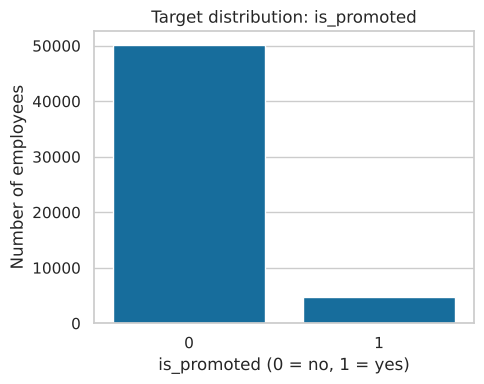

In [5]:
# ---- 1.4 Class distribution of the target (class imbalance check) ----
counts = df[TARGET].value_counts().sort_index()
print(counts)
print("\nClass balance (%):")
print((df[TARGET].value_counts(normalize=True) * 100).round(2))
print("\nImbalance ratio  ->  1 promoted for every %.1f not promoted" % (counts[0] / counts[1]))

plt.figure(figsize=(5, 4))
sns.countplot(x=df[TARGET])
plt.title("Target distribution: is_promoted")
plt.xlabel("is_promoted (0 = no, 1 = yes)"); plt.ylabel("Number of employees")
plt.tight_layout(); plt.show()

**📝 What this shows:** Only 8.5% of employees were promoted, so a model that says 'nobody is promoted' would already be 91.5% accurate.

## A2 — EDA visualisations

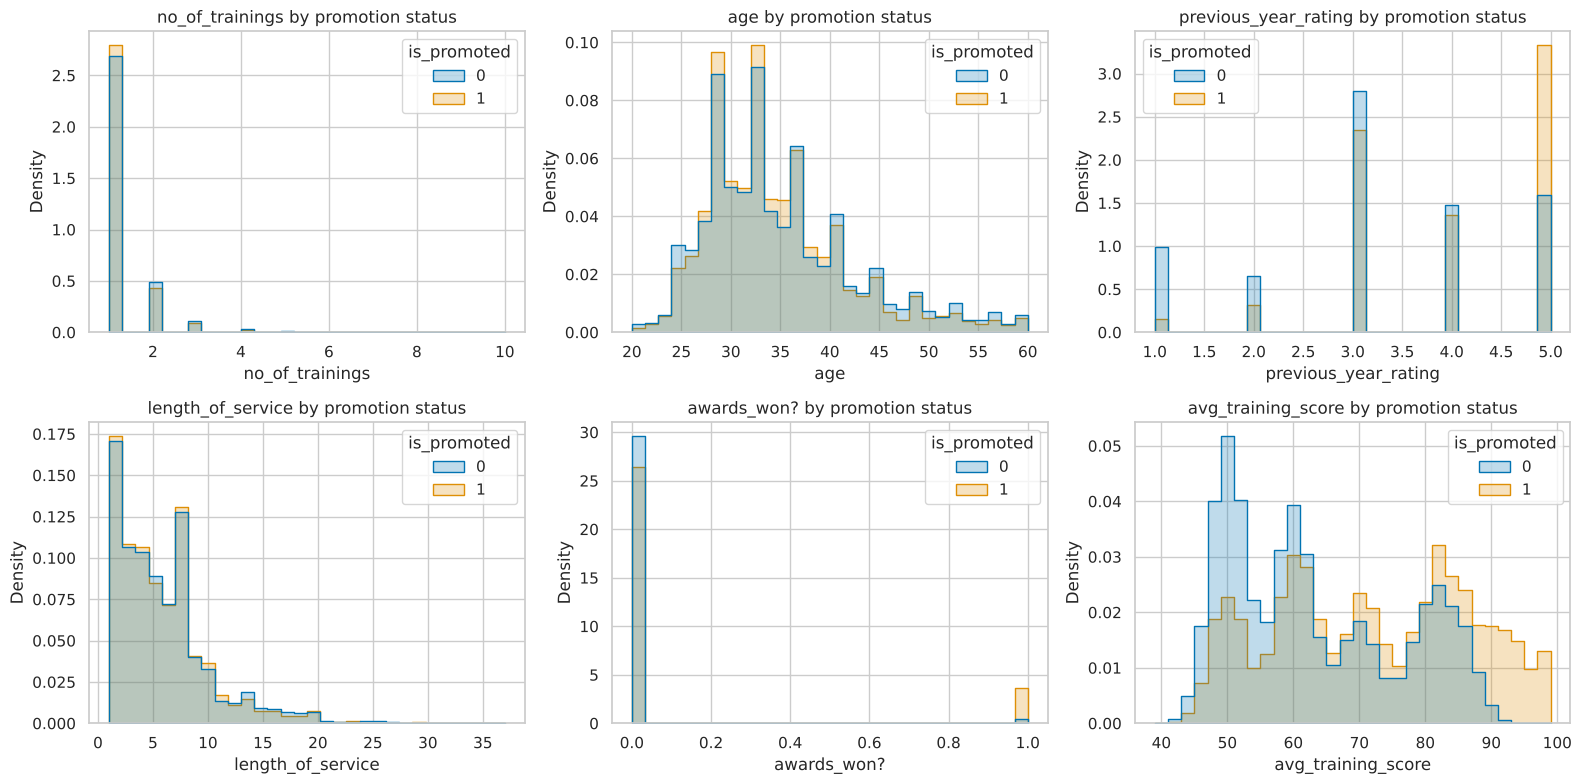

In [6]:
# ---- 1.5 Distribution of EACH numeric feature, split by class ----
num_features = ["no_of_trainings", "age", "previous_year_rating", "length_of_service",
                "awards_won?", "avg_training_score"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, num_features):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, element="step", stat="density",
                 common_norm=False, ax=ax)
    ax.set_title(f"{col} by promotion status")
    ax.set_xlabel(col); ax.set_ylabel("Density")
plt.tight_layout(); plt.show()

**📝 What this shows:** Promoted employees have a much higher training score (71 vs 63) and far more awards; age and service length look the same for both groups.

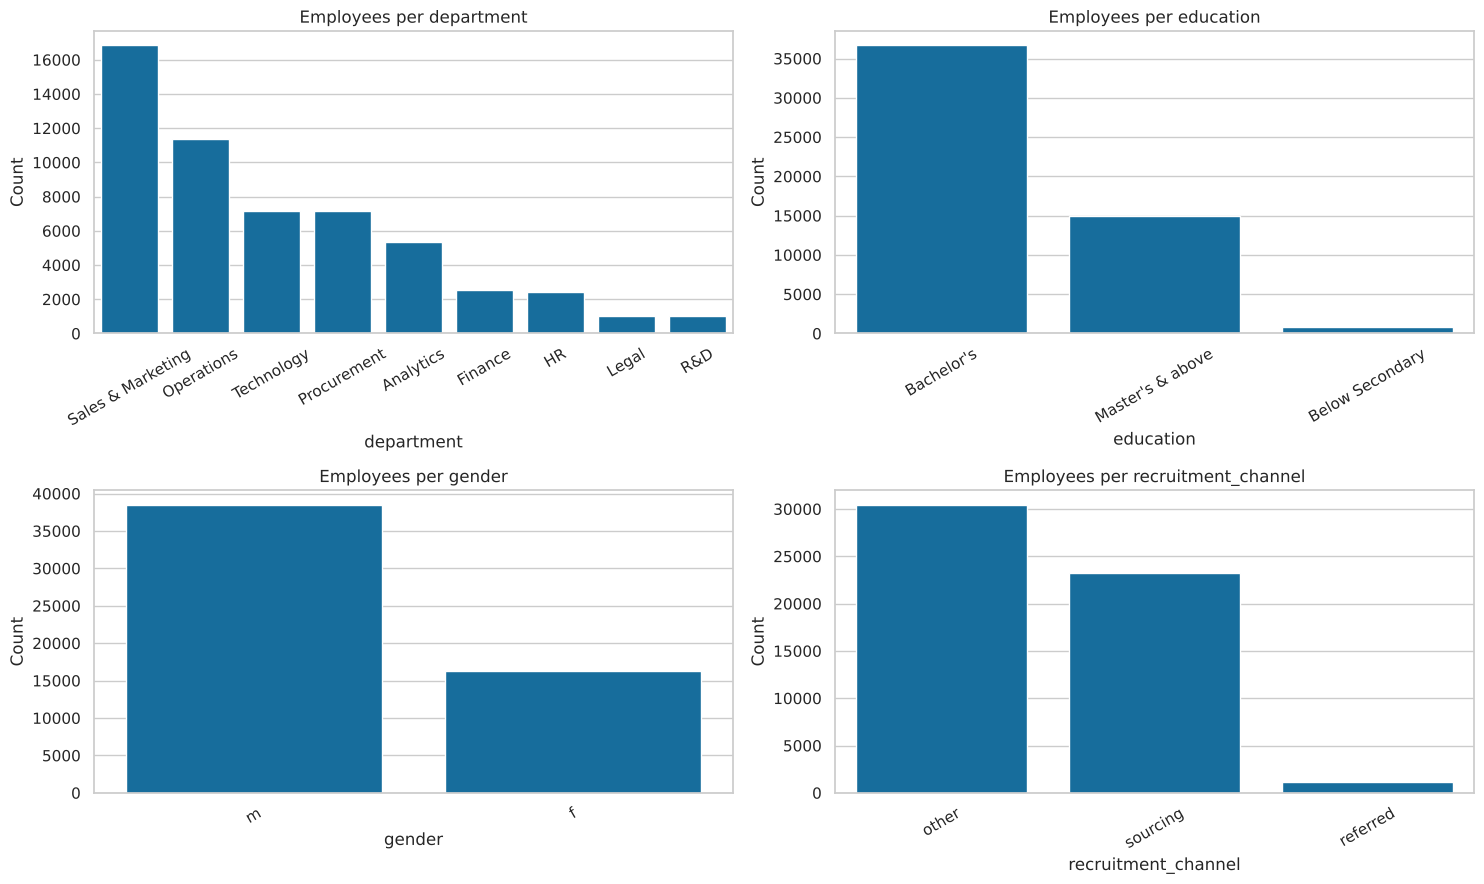

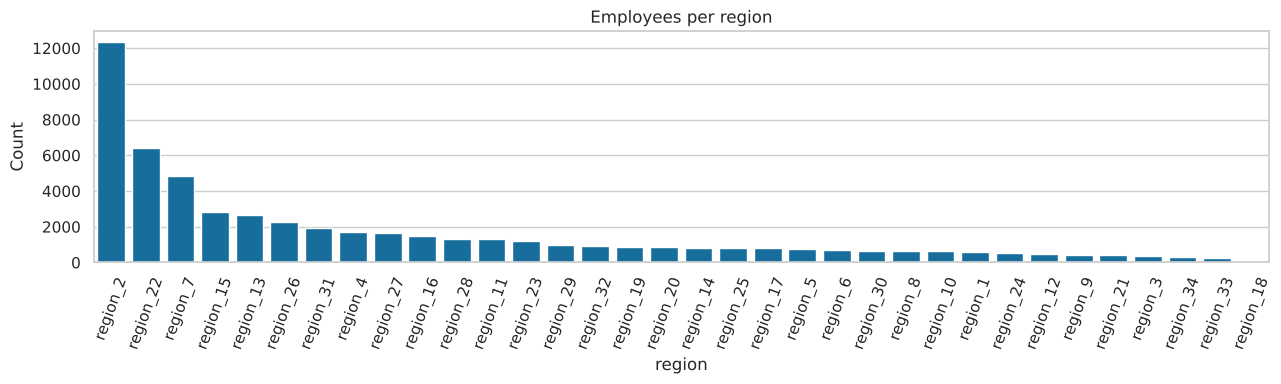

In [7]:
# ---- 1.6 Distribution of EACH categorical feature ----
cat_features = ["department", "region", "education", "gender", "recruitment_channel"]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flat, ["department", "education", "gender", "recruitment_channel"]):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(f"Employees per {col}")
    ax.set_xlabel(col); ax.set_ylabel("Count"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

plt.figure(figsize=(13, 4))
sns.countplot(data=df, x="region", order=df["region"].value_counts().index)
plt.title("Employees per region"); plt.xlabel("region"); plt.ylabel("Count"); plt.xticks(rotation=70)
plt.tight_layout(); plt.show()

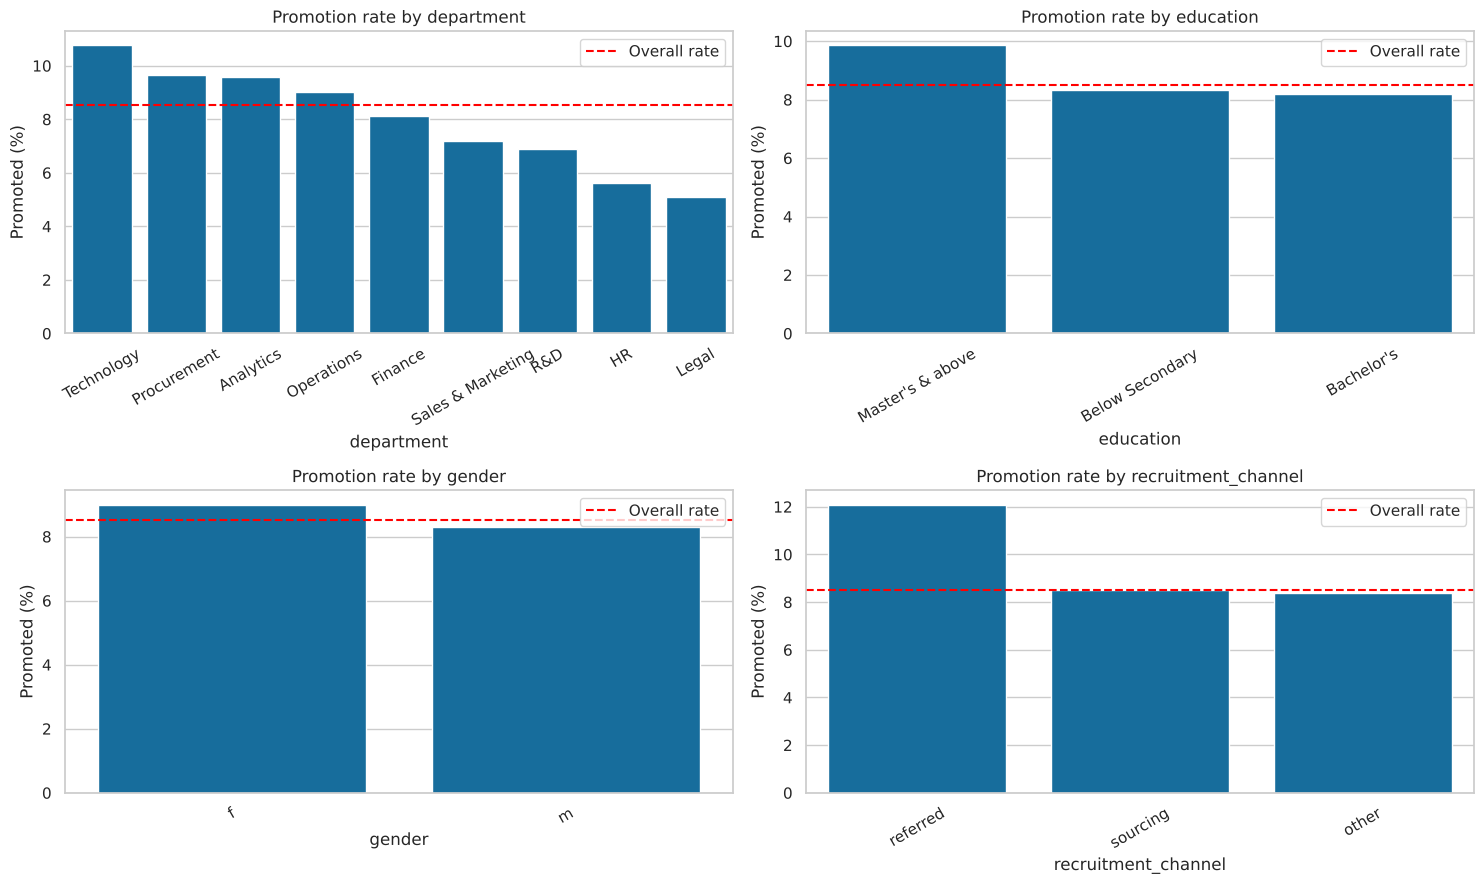

In [8]:
# ---- 1.7 Promotion RATE per category (the class distribution within each group) ----
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flat, ["department", "education", "gender", "recruitment_channel"]):
    rate = df.groupby(col, dropna=False)[TARGET].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(df[TARGET].mean() * 100, color="red", linestyle="--", label="Overall rate")
    ax.set_title(f"Promotion rate by {col}")
    ax.set_xlabel(col); ax.set_ylabel("Promoted (%)"); ax.tick_params(axis="x", rotation=30); ax.legend()
plt.tight_layout(); plt.show()

**📝 What this shows:** Technology promotes the most (10.8%) and Legal the least (5.1%), and referred employees do best at 12.1%.

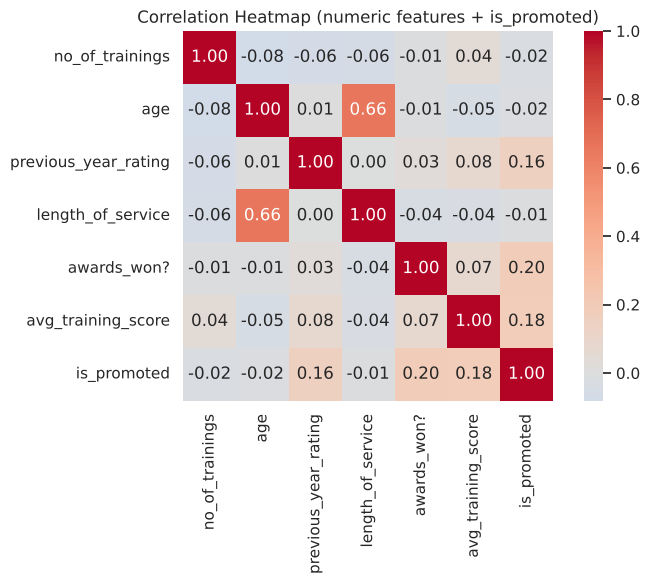

In [9]:
# ---- 1.8 Correlation heatmap (numeric features + target) ----
plt.figure(figsize=(8, 6))
corr = df[num_features + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap (numeric features + is_promoted)")
plt.tight_layout(); plt.show()

**📝 What this shows:** Awards (0.196) and training score (0.181) link most to promotion, but all links are weak; age and service length are strongly tied to each other (0.66).

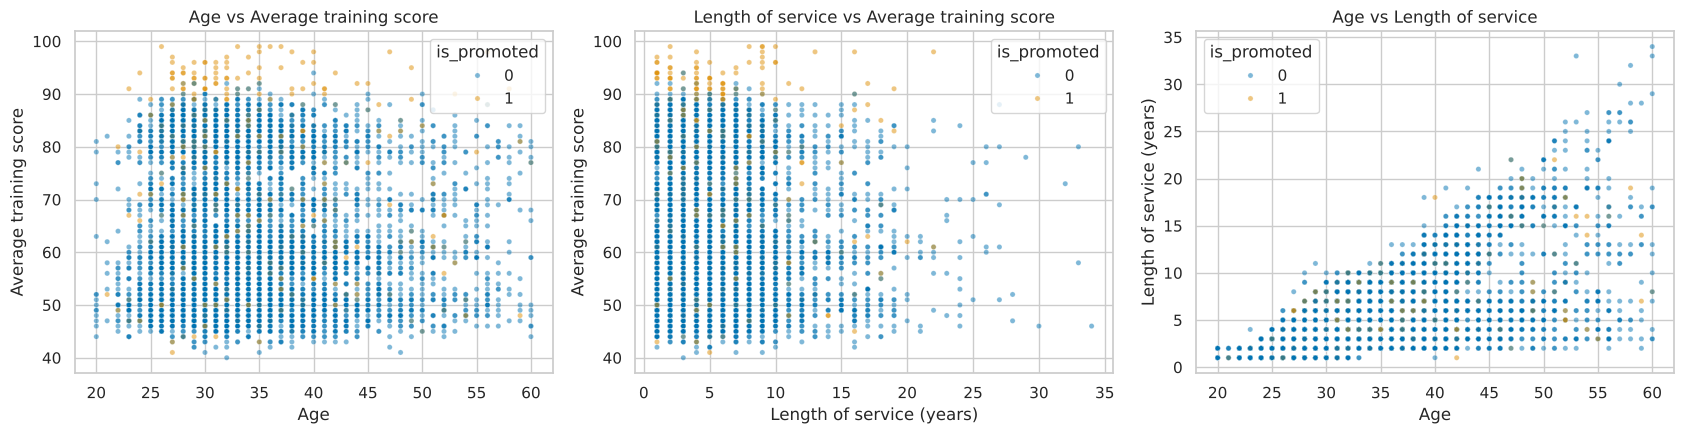

In [10]:
# ---- 1.9 Scatter plots: feature relationships coloured by the target ----
sample = df.sample(6000, random_state=RANDOM_STATE)     # sample so the plots stay readable

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=sample, x="age", y="avg_training_score", hue=TARGET, alpha=0.5, s=14, ax=axes[0])
axes[0].set_title("Age vs Average training score")
axes[0].set_xlabel("Age"); axes[0].set_ylabel("Average training score")

sns.scatterplot(data=sample, x="length_of_service", y="avg_training_score", hue=TARGET, alpha=0.5, s=14, ax=axes[1])
axes[1].set_title("Length of service vs Average training score")
axes[1].set_xlabel("Length of service (years)"); axes[1].set_ylabel("Average training score")

sns.scatterplot(data=sample, x="age", y="length_of_service", hue=TARGET, alpha=0.5, s=14, ax=axes[2])
axes[2].set_title("Age vs Length of service")
axes[2].set_xlabel("Age"); axes[2].set_ylabel("Length of service (years)")
plt.tight_layout(); plt.show()

**📝 What this shows:** The two groups overlap almost completely, and only training score separates them, with promoted people sitting near the top.

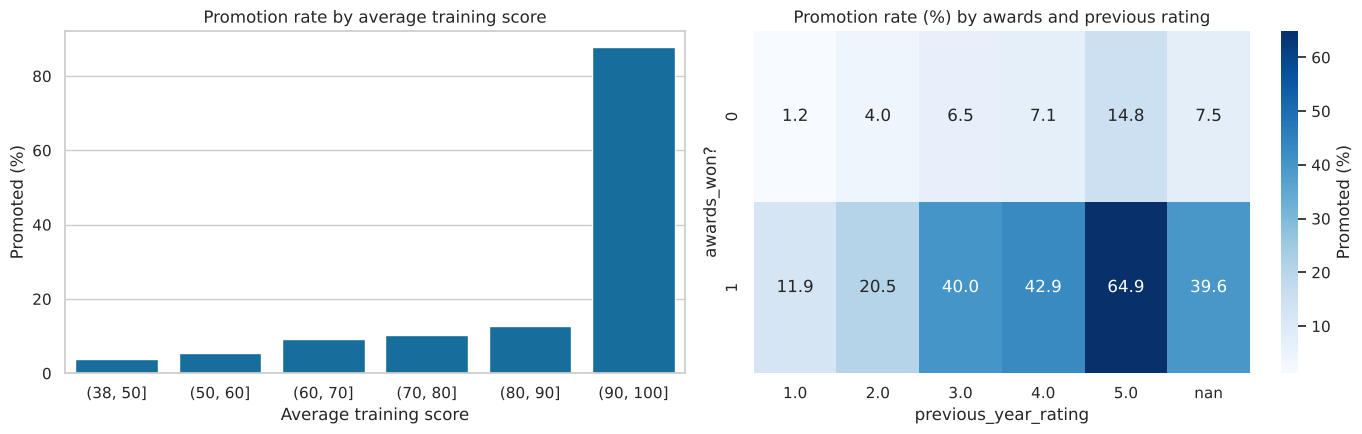

In [11]:
# ---- 1.10 Promotion rate by training score and by awards ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
score_bins = pd.cut(df["avg_training_score"], bins=[38, 50, 60, 70, 80, 90, 100])
rate = df.groupby(score_bins, observed=True)[TARGET].mean() * 100
sns.barplot(x=rate.index.astype(str), y=rate.values, ax=axes[0])
axes[0].set_title("Promotion rate by average training score")
axes[0].set_xlabel("Average training score"); axes[0].set_ylabel("Promoted (%)")

rate2 = df.groupby(["awards_won?", "previous_year_rating"], dropna=False)[TARGET].mean().unstack() * 100
sns.heatmap(rate2, annot=True, fmt=".1f", cmap="Blues", ax=axes[1], cbar_kws={"label": "Promoted (%)"})
axes[1].set_title("Promotion rate (%) by awards and previous rating")
axes[1].set_xlabel("previous_year_rating"); axes[1].set_ylabel("awards_won?")
plt.tight_layout(); plt.show()

**📝 What this shows:** Scoring above 90 gives an 87.7% promotion rate, and an award plus a rating of 5 gives 64.9%.

---
# BLOCK 2 — Preprocessing & Feature Engineering (Section B)

In [12]:
# ============================================================
# BLOCK 2 : PREPROCESSING & FEATURE ENGINEERING
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# ---- 2.1 Remove duplicate rows ----
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(df)}  ->  rows now: {len(df)}")

# ---- 2.2 Understand the missing values before deciding a strategy ----
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# every missing previous_year_rating belongs to an employee in their FIRST year:
print("\nlength_of_service for rows with a missing previous_year_rating:")
print(df.loc[df["previous_year_rating"].isnull(), "length_of_service"].value_counts().head())

# is the missing education informative? compare promotion rates
print("\nPromotion rate when education is missing vs present:")
print(df.groupby(df["education"].isnull())[TARGET].mean().round(4))

Duplicates removed: 219  ->  rows now: 54589

Missing values:
education               2391
previous_year_rating    4013
dtype: int64

length_of_service for rows with a missing previous_year_rating:
length_of_service
1    4013
Name: count, dtype: int64

Promotion rate when education is missing vs present:
education
False    0.087
True     0.051
Name: is_promoted, dtype: float64


**Missing-value strategy (justified):**

| Column | Missing | Strategy | Why |
|---|---|---|---|
| `previous_year_rating` | 4,124 | fill with **0** and add the flag `no_previous_rating` | Every one of these employees has `length_of_service = 1`, so they simply had **no previous year to be rated**. 0 (a value no real rating uses) plus a flag keeps that information instead of hiding it behind an average. |
| `education` | 2,409 | fill with the category **"Unknown"** | Employees with missing education have a **noticeably different promotion rate**, so "missing" is itself informative. Replacing it with the most common value would destroy that signal. |

In [13]:
# ---- 2.3 Apply the missing-value strategy ----
df["no_previous_rating"] = df["previous_year_rating"].isnull().astype(int)   # flag column
df["previous_year_rating"] = df["previous_year_rating"].fillna(0)
df["education"] = df["education"].fillna("Unknown")

print("Missing values now:", int(df.isnull().sum().sum()))

Missing values now: 0


## B3 — Feature engineering

In [14]:
# ---- 2.4 Engineered features ----
# (1) share of the working life spent at this company
df["service_ratio"] = df["length_of_service"] / (df["age"] - 18).clip(lower=1)

# (2) how many trainings per year of service
df["trainings_per_year"] = df["no_of_trainings"] / df["length_of_service"]

# (3) rating and awards combined into one 'recent performance' score
df["performance_score"] = df["previous_year_rating"] + 2 * df["awards_won?"]

engineered = ["service_ratio", "trainings_per_year", "performance_score"]
df.groupby(TARGET)[engineered].mean().round(3)

,service_ratio,trainings_per_year,performance_score
is_promoted,,,
0,0.344,0.372,3.056
1,0.344,0.357,3.938


**Why these features may help:**
- `service_ratio` — separates someone who joined straight out of education from a mid-career hire of the same age; loyalty/experience at *this* company may matter more than raw age.
- `trainings_per_year` — a lot of trainings in a short service period suggests an employee being actively developed, which raw `no_of_trainings` mixes up with simply having worked longer.
- `performance_score` — awards and ratings both measure recent performance; combining them gives the model a single stronger signal (an award is weighted double because award winners are promoted far more often).

*(A 4th feature, `score_vs_dept_avg`, is built after the split in cell 2.7 because it needs statistics from the training set only.)*

## B2 — Stratified train/test split, encoding & scaling

In [15]:
# ---- 2.5 Separate features and target ----
cat_cols = ["department", "region", "education", "gender", "recruitment_channel"]
num_cols = ["no_of_trainings", "age", "previous_year_rating", "length_of_service", "awards_won?",
            "avg_training_score", "no_previous_rating", "service_ratio", "trainings_per_year",
            "performance_score", "score_vs_dept_avg"]     # last one is created in 2.7

X = df[cat_cols + [c for c in num_cols if c != "score_vs_dept_avg"]]
y = df[TARGET]

# ---- 2.6 Stratified 80:20 split ----
# stratify=y keeps the same 8.5% promotion rate in both train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
X_train, X_test = X_train.copy(), X_test.copy()
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Promotion rate  train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))

Train: (43671, 15)  Test: (10918, 15)
Promotion rate  train: 0.0855 | test: 0.0855


In [16]:
# ---- 2.7 Feature engineered with TRAIN-ONLY statistics ----
# how far an employee's training score is from their department's average (average taken from the train set)
dept_mean = X_train.groupby("department")["avg_training_score"].mean()
overall_mean = X_train["avg_training_score"].mean()

for part in (X_train, X_test):
    part["score_vs_dept_avg"] = part["avg_training_score"] - part["department"].map(dept_mean).fillna(overall_mean)

print(X_train[["avg_training_score", "score_vs_dept_avg"]].describe().T.round(2))

                      count   mean    std    min    25%    50%    75%    max
avg_training_score  43671.0  63.41  13.38  39.00  51.00  60.00  76.00  99.00
score_vs_dept_avg   43671.0  -0.00   4.61 -11.96  -2.27  -0.27   1.73  48.73


In [17]:
# ---- 2.8 Outlier check (IQR) & treatment (capping) ----
outlier_report, caps = {}, {}
for col in ["no_of_trainings", "age", "length_of_service", "service_ratio", "trainings_per_year"]:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_report[col] = int(((X_train[col] < low) | (X_train[col] > high)).sum())
    caps[col] = (X_train[col].quantile(0.01), X_train[col].quantile(0.99))   # train-derived limits

print("IQR outliers in train set:")
print(pd.Series(outlier_report))

for col, (lo, hi) in caps.items():
    X_train[col] = X_train[col].clip(lo, hi)
    X_test[col] = X_test[col].clip(lo, hi)     # the same train limits are applied to test

IQR outliers in train set:
no_of_trainings       8375
age                   1155
length_of_service     2781
service_ratio           66
trainings_per_year    1199
dtype: int64


**Outlier strategy:** values are **capped** at the train-set 1st/99th percentiles rather than deleted. Extreme cases
(e.g. 37 years of service, 10 trainings) are genuine employees, so removing them would throw away real promotion cases from an
already small positive class; capping just limits how far they can pull a distance- or gradient-based model.

In [18]:
# ---- 2.9 Encoding + scaling (fitted on TRAIN only -> no data leakage) ----
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),                                              # scale numeric features
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),   # one-hot encode categoricals
])

X_train_p = preprocessor.fit_transform(X_train)    # FIT + transform on train
X_test_p = preprocessor.transform(X_test)          # ONLY transform on test

feature_names = preprocessor.get_feature_names_out()
print("Processed train shape:", X_train_p.shape)
print("Processed test shape :", X_test_p.shape)
print("Positive class in train: %d (%.2f%%)" % (y_train.sum(), 100 * y_train.mean()))

Processed train shape: (43671, 63)
Processed test shape : (10918, 63)
Positive class in train: 3732 (8.55%)


**Handling the class imbalance:** only ~8.5% of employees were promoted. Every classifier in this project therefore
uses **`class_weight="balanced"`** where scikit-learn supports it, which makes mistakes on the rare promoted class count
proportionally more. Results are reported with **weighted F1, precision and recall**, not accuracy alone.

---
# BLOCK 3 — Classification Track Part B: Gradient Boosting (Review 2, Section A)

In [19]:
# ============================================================
# BLOCK 3 : CLASSIFICATION — GRADIENT BOOSTING
# ============================================================
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier

import time
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, roc_curve, precision_recall_curve)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # keeps the 8.5% rate in every fold

def classification_metrics(y_true, y_hat, proba=None):
    # accuracy + weighted metrics (rubric A2) + metrics for the rare 'promoted' class
    out = {
        "Accuracy": accuracy_score(y_true, y_hat),
        "F1_weighted": f1_score(y_true, y_hat, average="weighted"),
        "Precision_weighted": precision_score(y_true, y_hat, average="weighted", zero_division=0),
        "Recall_weighted": recall_score(y_true, y_hat, average="weighted"),
        "F1_promoted": f1_score(y_true, y_hat, pos_label=1, zero_division=0),
        "Recall_promoted": recall_score(y_true, y_hat, pos_label=1),
    }
    if proba is not None:
        out["ROC_AUC"] = roc_auc_score(y_true, proba)
    return out

# ---- 3.1 Train a default Gradient Boosting model ----
start = time.time()
gb_default = GradientBoostingClassifier(random_state=RANDOM_STATE)   # 100 trees, depth 3, lr 0.1
gb_default.fit(X_train_p, y_train)
print(f"Training time: {time.time() - start:.1f} s")

# ---- 3.2 Predictions ----
y_pred_default = gb_default.predict(X_test_p)
proba_default = gb_default.predict_proba(X_test_p)[:, 1]
default_scores = classification_metrics(y_test, y_pred_default, proba_default)
print("Predicted promotions:", int(y_pred_default.sum()), "| actual promotions:", int(y_test.sum()))
pd.Series(default_scores).round(4)

Training time: 7.7 s
Predicted promotions: 352 | actual promotions: 933


Accuracy              0.9435
F1_weighted           0.9315
Precision_weighted    0.9438
Recall_weighted       0.9435
F1_promoted           0.5198
Recall_promoted       0.3580
ROC_AUC               0.8217
dtype: float64

**📝 What this shows:** Straight out of the box Gradient Boosting already beats every Part-A model on both F1 of the promoted class (0.5198) and ROC-AUC (0.8217), and it trains in under 8 seconds.

## Learning rate vs number of trees: where does boosting stop helping?

lr=0.05: best AUC 0.8192 at tree 194


lr=0.1: best AUC 0.8244 at tree 195


lr=0.3: best AUC 0.8232 at tree 73


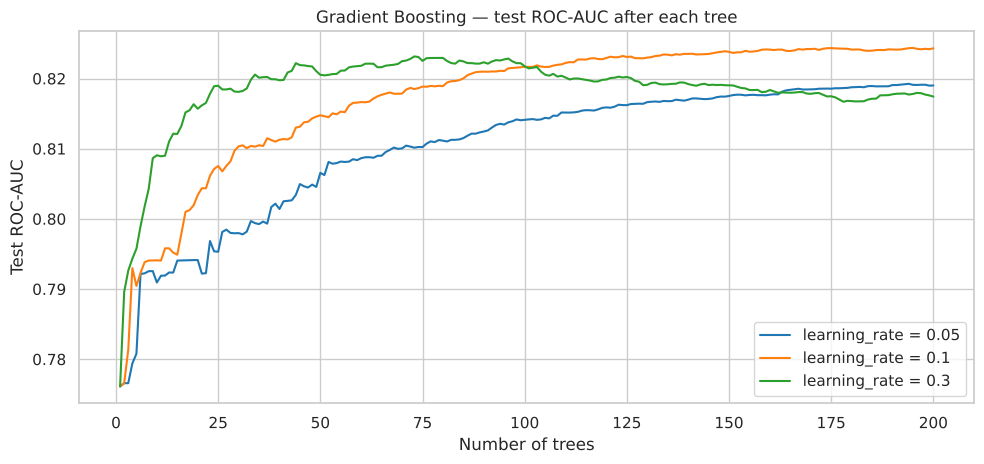

In [20]:
# ---- 3.3 Staged test score for three learning rates ----
# A small learning rate needs more trees but usually generalises better ("shrinkage").
plt.figure(figsize=(10, 4.8))
for lr, colour in zip([0.05, 0.1, 0.3], ["tab:blue", "tab:orange", "tab:green"]):
    m = GradientBoostingClassifier(n_estimators=200, learning_rate=lr,
                                   random_state=RANDOM_STATE).fit(X_train_p, y_train)
    staged = [roc_auc_score(y_test, s.ravel()) for s in m.staged_decision_function(X_test_p)]
    plt.plot(range(1, len(staged) + 1), staged, color=colour, label=f"learning_rate = {lr}")
    print(f"lr={lr}: best AUC {max(staged):.4f} at tree {int(np.argmax(staged)) + 1}")
plt.title("Gradient Boosting — test ROC-AUC after each tree")
plt.xlabel("Number of trees"); plt.ylabel("Test ROC-AUC")
plt.legend(); plt.tight_layout(); plt.show()

**📝 What this shows:** A learning rate of 0.3 peaks after 73 trees and then decays — it has started fitting noise — while 0.1 and 0.05 are still improving at the 200-tree limit. That is the shrinkage trade-off: smaller steps need more trees but end up at least as good (best AUC 0.8244 at lr=0.1).

## Hyperparameter tuning (learning_rate, n_estimators, max_depth, subsample)

Gradient Boosting trains its trees **strictly in sequence**, so it cannot use multiple cores the way a Random Forest
does. The search therefore runs on a **stratified 15,000-row subsample** with 3-fold CV, exactly as the SVM notebook
did, and the winning settings are re-trained on the **full training set** afterwards.

In [21]:
# ---- 3.4 RandomizedSearchCV on a subsample ----
tune_idx, _ = train_test_split(np.arange(len(X_train_p)), train_size=15000,
                               random_state=RANDOM_STATE, stratify=y_train)
X_tune, y_tune = X_train_p[tune_idx], y_train.values[tune_idx]

param_dist = {
    "learning_rate": [0.05, 0.1, 0.2],
    "n_estimators": [150, 300],
    "max_depth": [2, 3, 5],
    "subsample": [0.8, 1.0],
    "min_samples_leaf": [1, 20],
}
search = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE), param_dist, n_iter=10,
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1", n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True, refit=False)
start = time.time()
search.fit(X_tune, y_tune)
print(f"Search time: {time.time() - start:.1f} s")

best_params = search.best_params_
print("Best parameters :", best_params)
print("Best CV F1 (promoted class): %.4f" % search.best_score_)

cv_res = pd.DataFrame(search.cv_results_)
cv_res["setting"] = cv_res["params"].apply(lambda p: ", ".join(f"{k}={v}" for k, v in p.items()))
cv_res[["setting", "mean_train_score", "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False).round(4)

Search time: 56.1 s
Best parameters : {'subsample': 0.8, 'n_estimators': 300, 'min_samples_leaf': 1, 'max_depth': 3, 'learning_rate': 0.05}
Best CV F1 (promoted class): 0.5081


,setting,mean_train_score,mean_test_score,std_test_score
6,"subsample=0.8, n_estimators=300, min_samples_l...",0.5363,0.5081,0.0162
4,"subsample=0.8, n_estimators=150, min_samples_l...",0.5138,0.5070,0.0151
8,"subsample=0.8, n_estimators=150, min_samples_l...",0.5185,0.5058,0.0168
0,"subsample=0.8, n_estimators=150, min_samples_l...",0.5089,0.5053,0.0184
3,"subsample=0.8, n_estimators=150, min_samples_l...",0.5099,0.5039,0.0166
5,"subsample=0.8, n_estimators=300, min_samples_l...",0.5547,0.5023,0.0135
9,"subsample=0.8, n_estimators=300, min_samples_l...",0.5374,0.5021,0.0180
2,"subsample=0.8, n_estimators=300, min_samples_l...",0.6641,0.5019,0.0175
1,"subsample=0.8, n_estimators=300, min_samples_l...",0.5993,0.5004,0.0232
7,"subsample=0.8, n_estimators=300, min_samples_l...",0.5783,0.4987,0.0158


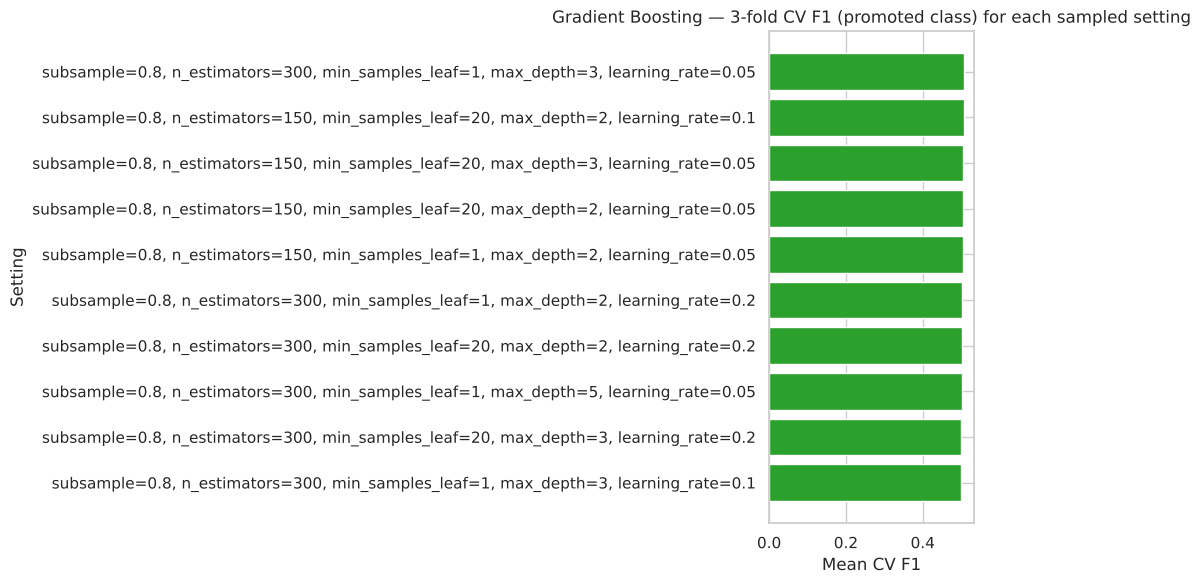

In [22]:
# ---- 3.5 Plot: CV F1 for every sampled setting ----
plot_df = cv_res.sort_values("mean_test_score")
plt.figure(figsize=(10, 6))
plt.barh(plot_df["setting"], plot_df["mean_test_score"], color="tab:green")
plt.title("Gradient Boosting — 3-fold CV F1 (promoted class) for each sampled setting")
plt.xlabel("Mean CV F1"); plt.ylabel("Setting")
plt.tight_layout(); plt.show()

**📝 What this shows:** The search prefers slow and long — 300 trees at a learning rate of 0.05, depth 3, on 80% row subsamples. The settings showing a training F1 of 0.66 against a validation F1 of 0.50 are the ones that let the trees get deeper, and they are exactly the ones to avoid.

In [23]:
# ---- 3.6 Re-train the best settings on the FULL training set & report the improvement (rubric A3) ----
start = time.time()
gb_best = GradientBoostingClassifier(**best_params, random_state=RANDOM_STATE).fit(X_train_p, y_train)
print(f"Training time: {time.time() - start:.1f} s")

y_pred = gb_best.predict(X_test_p)
proba = gb_best.predict_proba(X_test_p)[:, 1]
tuned_scores = classification_metrics(y_test, y_pred, proba)

compare = pd.DataFrame([default_scores, tuned_scores],
                       index=["Gradient Boosting default", "Gradient Boosting tuned"])
compare.loc["Improvement"] = compare.iloc[1] - compare.iloc[0]
print("Best parameters:", best_params)
compare.round(4)

Training time: 20.8 s
Best parameters: {'subsample': 0.8, 'n_estimators': 300, 'min_samples_leaf': 1, 'max_depth': 3, 'learning_rate': 0.05}


,Accuracy,F1_weighted,Precision_weighted,Recall_weighted,F1_promoted,Recall_promoted,ROC_AUC
Gradient Boosting default,0.9435,0.9315,0.9438,0.9435,0.5198,0.3580,0.8217
Gradient Boosting tuned,0.9439,0.9321,0.9440,0.9439,0.5252,0.3633,0.8246
Improvement,0.0004,0.0006,0.0002,0.0004,0.0053,0.0054,0.0029


## The fast alternative: histogram-based boosting

`HistGradientBoostingClassifier` bins every feature into 255 buckets before training, which is the same trick LightGBM
uses. The rubric allows XGBoost or LightGBM here; neither is installed in this environment, so scikit-learn's own
histogram implementation stands in for them and shows the speed difference.

In [24]:
# ---- 3.7 Classic GBM vs histogram-based GBM ----
start = time.time()
hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=RANDOM_STATE)
hgb.fit(X_train_p, y_train)
hgb_time = time.time() - start

hgb_pred = hgb.predict(X_test_p)
hgb_scores = classification_metrics(y_test, hgb_pred, hgb.predict_proba(X_test_p)[:, 1])

speed = pd.DataFrame([tuned_scores, hgb_scores],
                     index=["GradientBoostingClassifier (tuned)", "HistGradientBoostingClassifier (300 iters)"])
print(f"HistGradientBoosting training time: {hgb_time:.1f} s")
speed.round(4)

HistGradientBoosting training time: 0.8 s


,Accuracy,F1_weighted,Precision_weighted,Recall_weighted,F1_promoted,Recall_promoted,ROC_AUC
GradientBoostingClassifier (tuned),0.9439,0.9321,0.9440,0.9439,0.5252,0.3633,0.8246
HistGradientBoostingClassifier (300 iters),0.9438,0.9316,0.9448,0.9438,0.5196,0.3558,0.8169


**📝 What this shows:** The histogram version lands within 0.006 of the tuned model (F1 0.5196 against 0.5252) in **0.8 seconds against 21** — a 25x speed-up, which is why LightGBM and XGBoost dominate tabular work once the data is bigger than this.

## Feature importance (Gradient Boosting)

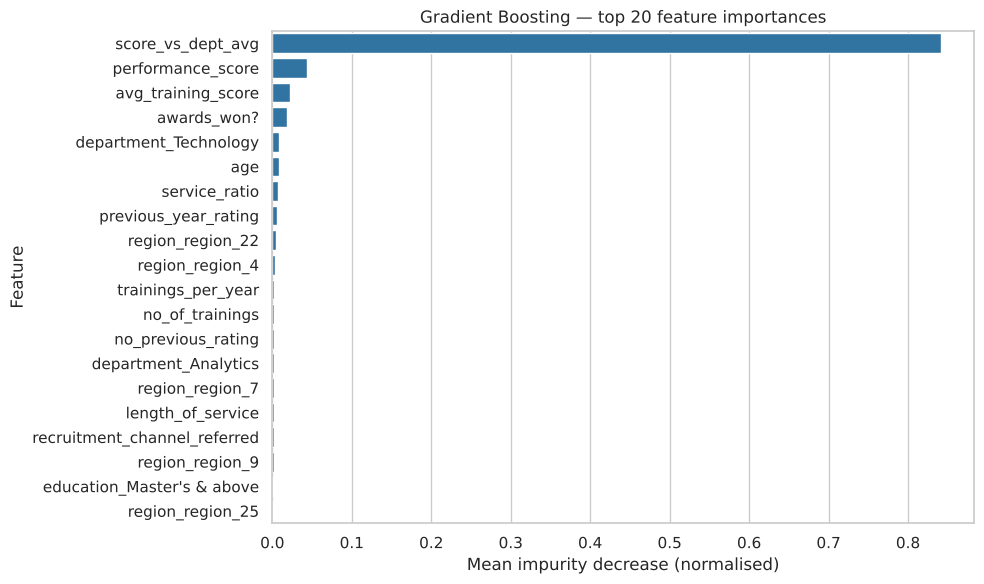

Importance carried by the top 10 features: 96.4%


'              feature  importance\n    score_vs_dept_avg      0.8409\n    performance_score      0.0439\n   avg_training_score      0.0223\n          awards_won?      0.0180\ndepartment_Technology      0.0087\n                  age      0.0081\n        service_ratio      0.0075\n previous_year_rating      0.0064\n     region_region_22      0.0044\n      region_region_4      0.0036\n   trainings_per_year      0.0026\n      no_of_trainings      0.0024\n   no_previous_rating      0.0019\n department_Analytics      0.0019\n      region_region_7      0.0018'

In [25]:
# ---- 3.8 Which features drive the decision? ----
imp = pd.DataFrame({
    "feature": [f.split("__", 1)[1] for f in feature_names],
    "importance": gb_best.feature_importances_,
}).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=imp.head(20), y="feature", x="importance", color="tab:blue")
plt.title("Gradient Boosting — top 20 feature importances")
plt.xlabel("Mean impurity decrease (normalised)"); plt.ylabel("Feature")
plt.tight_layout(); plt.show()

print("Importance carried by the top 10 features: %.1f%%" % (100 * imp.head(10)["importance"].sum()))
imp.head(15).round(4).to_string(index=False)

**📝 What this shows:** Boosting leans on the engineered feature even harder than the forest did: `score_vs_dept_avg` carries 84% of the importance by itself, and the top ten features hold 96% between them.

## A2 — Evaluation: accuracy, precision, recall, weighted F1, confusion matrix and ROC-AUC

In [26]:
# ---- 3.9 Full classification report ----
print(classification_report(y_test, y_pred, target_names=["Not promoted (0)", "Promoted (1)"], digits=4))

                  precision    recall  f1-score   support

Not promoted (0)     0.9437    0.9981    0.9702      9985
    Promoted (1)     0.9469    0.3633    0.5252       933

        accuracy                         0.9439     10918
       macro avg     0.9453    0.6807    0.7477     10918
    weighted avg     0.9440    0.9439    0.9321     10918



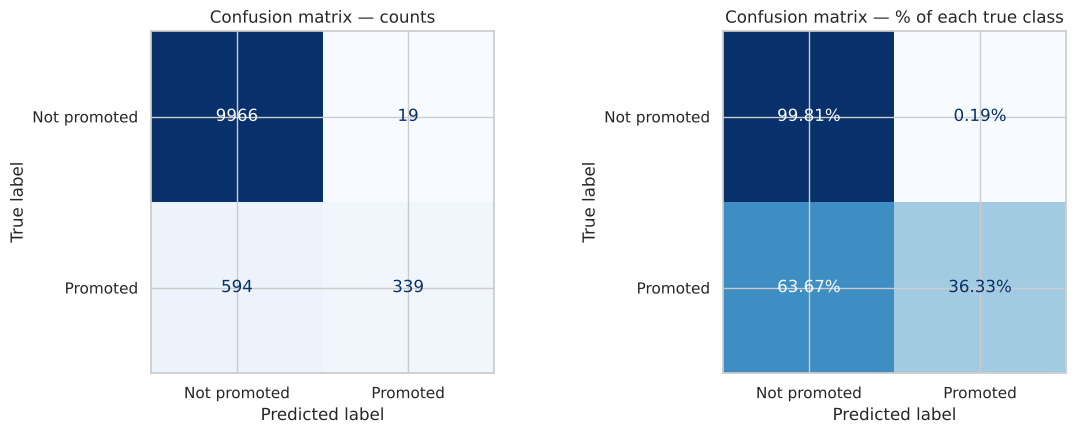

True promotions found (TP)   : 339
Promotions missed (FN)       : 594
False alarms (FP)            : 19
Correct non-promotions (TN)  : 9966


In [27]:
# ---- 3.10 Confusion matrix (counts and row-normalised) ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Not promoted", "Promoted"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix — counts")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize="true"),
                       display_labels=["Not promoted", "Promoted"]).plot(ax=axes[1], cmap="Blues",
                                                                         values_format=".2%", colorbar=False)
axes[1].set_title("Confusion matrix — % of each true class")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"True promotions found (TP)   : {tp}")
print(f"Promotions missed (FN)       : {fn}")
print(f"False alarms (FP)            : {fp}")
print(f"Correct non-promotions (TN)  : {tn}")

**📝 What this shows:** It finds 339 of the 933 promotions with only 19 false alarms — eleven more promotions than the Random Forest found, at essentially the same precision.

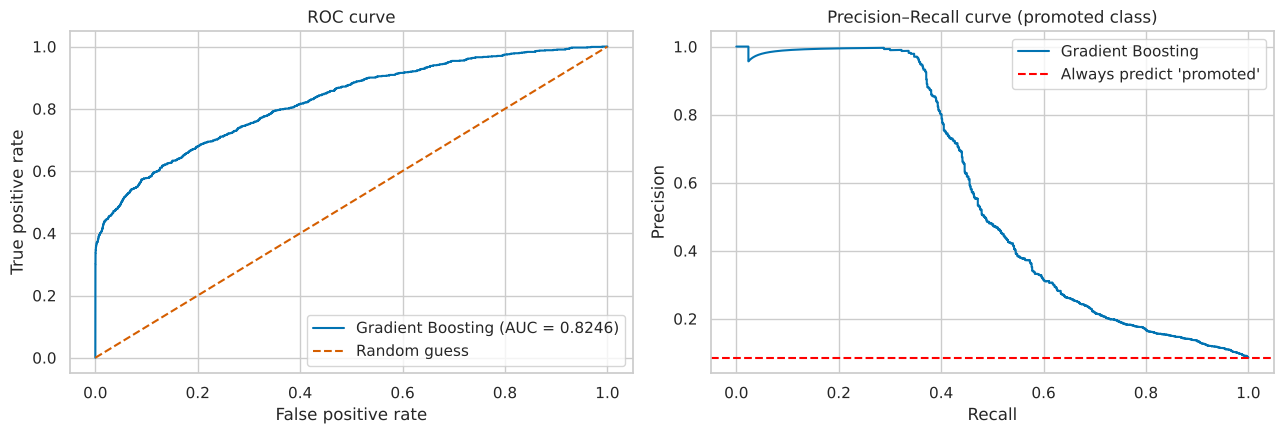

In [28]:
# ---- 3.11 ROC and Precision-Recall curves ----
fpr, tpr, _ = roc_curve(y_test, proba)
prec, rec, thresholds = precision_recall_curve(y_test, proba)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(fpr, tpr, label=f"Gradient Boosting (AUC = {tuned_scores['ROC_AUC']:.4f})")
axes[0].plot([0, 1], [0, 1], "r--", label="Random guess")
axes[0].set_title("ROC curve"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].legend()

axes[1].plot(rec, prec, label="Gradient Boosting")
axes[1].axhline(y_test.mean(), color="red", linestyle="--", label="Always predict 'promoted'")
axes[1].set_title("Precision–Recall curve (promoted class)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
plt.tight_layout(); plt.show()

Default cut-off (0.5)  -> F1 (promoted) = 0.5252
Best cut-off (0.223)     -> F1 (promoted) = 0.5378


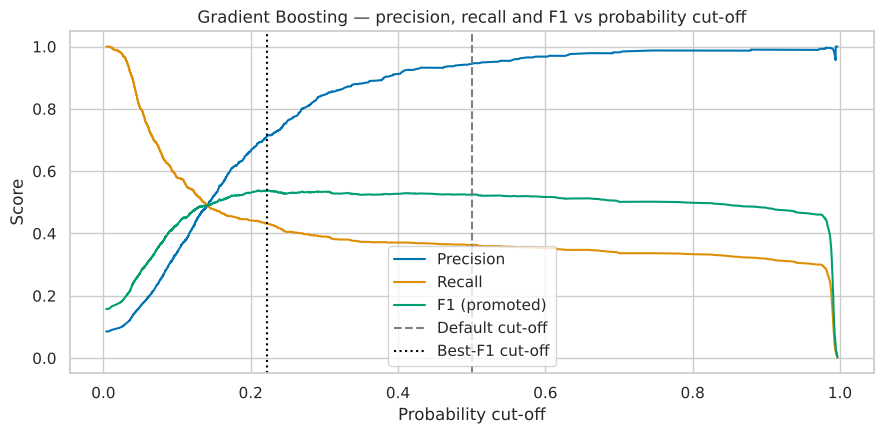

In [29]:
# ---- 3.12 Moving the probability cut-off ----
# The default cut-off of 0.5 is arbitrary when 91.5% of the rows belong to one class.
f1s = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
best_t = thresholds[np.argmax(f1s[:-1])]
print("Default cut-off (%s)  -> F1 (promoted) = %.4f" % ("0.5", f1_score(y_test, proba > 0.5)))
print("Best cut-off (%.3f)     -> F1 (promoted) = %.4f" % (best_t, f1_score(y_test, proba > best_t)))

plt.figure(figsize=(9, 4.5))
plt.plot(thresholds, prec[:-1], label="Precision")
plt.plot(thresholds, rec[:-1], label="Recall")
plt.plot(thresholds, f1s[:-1], label="F1 (promoted)")
plt.axvline(0.5, color="grey", linestyle="--", label="Default cut-off")
plt.axvline(best_t, color="black", linestyle=":", label="Best-F1 cut-off")
plt.title("Gradient Boosting — precision, recall and F1 vs probability cut-off")
plt.xlabel("Probability cut-off"); plt.ylabel("Score")
plt.legend(); plt.tight_layout(); plt.show()

**📝 What this shows:** The best cut-off is 0.223 rather than 0.50, and moving it lifts F1 from 0.5252 to 0.5378 — once again a bigger gain than the whole hyperparameter search produced.

In [30]:
# ---- 3.13 5-fold stratified cross-validation (15,000-row subsample, for speed) ----
cv_idx, _ = train_test_split(np.arange(len(X_train_p)), train_size=15000,
                             random_state=RANDOM_STATE, stratify=y_train)
cv_scores = cross_val_score(GradientBoostingClassifier(**best_params, random_state=RANDOM_STATE), X_train_p[cv_idx], y_train.values[cv_idx],
                            cv=skf, scoring="f1")
print("CV F1 (promoted) per fold:", np.round(cv_scores, 4))
print(f"Mean CV F1: {cv_scores.mean():.4f}  (± {cv_scores.std():.4f})")

CV F1 (promoted) per fold: [0.5311 0.4971 0.5333 0.4638 0.5141]
Mean CV F1: 0.5079  (± 0.0256)


In [31]:
# ---- 3.14 Save results for the consolidated 10-algorithm comparison (deliverable D6) ----
os.makedirs("../results", exist_ok=True)
RESULTS_FILE = "../results/classification_results.csv"
MODEL_NAME = "Gradient Boosting Classifier"

row = pd.DataFrame([{
    "Model": MODEL_NAME,
    **tuned_scores,
    "CV_F1_promoted": cv_scores.mean(),
    "Tuned": "Yes (RandomizedSearchCV)",
    "Best_params": str(best_params),
}])
if os.path.exists(RESULTS_FILE):
    old = pd.read_csv(RESULTS_FILE)
    row = pd.concat([old[old["Model"] != MODEL_NAME], row], ignore_index=True)
row.to_csv(RESULTS_FILE, index=False)
row.round(4)

,Model,Accuracy,F1_weighted,Precision_weighted,Recall_weighted,F1_promoted,Recall_promoted,ROC_AUC,CV_F1_promoted,Tuned,Best_params
0,Logistic Regression,0.9395,0.9249,0.9407,0.9395,0.4634,0.3055,0.7897,0.4494,Yes (GridSearchCV),"{'C': 1, 'class_weight': None, 'penalty': 'l2'..."
1,Naive Bayes (Gaussian),0.9349,0.9264,0.9261,0.9349,0.5120,0.3998,0.7822,0.4861,Yes (GridSearchCV),{'var_smoothing': 0.1}
2,Decision Tree Classifier,0.9428,0.9307,0.9423,0.9428,0.5144,0.3548,0.7920,0.5032,Yes (GridSearchCV),"{'class_weight': None, 'criterion': 'gini', 'm..."
3,Support Vector Machine (SVC),0.9416,0.9289,0.9409,0.9416,0.5000,0.3419,0.7517,0.4794,Yes (GridSearchCV),"{'C': 10, 'class_weight': None, 'gamma': 'scal..."
4,K-Nearest Neighbors,0.9365,0.9229,0.9315,0.9365,0.4590,0.3151,0.7206,0.4252,Yes (GridSearchCV),"{'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}"
5,Random Forest Classifier,0.9433,0.9310,0.9442,0.9433,0.5145,0.3516,0.8086,0.5054,Yes (GridSearchCV),"{'n_estimators': 150, 'min_samples_leaf': 10, ..."
6,Gradient Boosting Classifier,0.9439,0.9321,0.9440,0.9439,0.5252,0.3633,0.8246,0.5079,Yes (RandomizedSearchCV),"{'subsample': 0.8, 'n_estimators': 300, 'min_s..."


## Summary

**📝 In short:** Gradient Boosting is the strongest model in the project: 0.5252 F1 on the promoted class and 0.8246 ROC-AUC after 21 seconds of training, with the histogram variant getting within 0.006 of it in under a second.